# Multilayer Perceptron: Employee Resignation Prediction
**Student ID: IT25100142 — supplementary MLP**

I test a simple neural network as a comparison with FT-Transformer. An MLP passes the inputs through hidden layers to produce a resignation score. It does not use attention.

This notebook explains preprocessing, eight settings, five-fold nested training and measured results. Opening it defaults to saved-result review. MLP is a supplementary comparison for the FT-Transformer contribution.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Code

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/feature_contract.yaml").exists())
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.precision", 6)
RUN_TRAINING = False
if RUN_TRAINING:
    import sys
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    from src.models.mlp_experiment import run
    run(ROOT)  # A new run directory; never overwrites an earlier experiment.

base = ROOT / "results/models/mlp/individual_IT25100142"
pointer = base / "latest_run.json"
if not pointer.exists():
    raise FileNotFoundError("No completed MLP run found. Supply the project data and enable RUN_TRAINING to create one.")
out = ROOT / json.loads(pointer.read_text())["directory"]
summary = json.loads((out / "summary_metrics.json").read_text())
manifest = json.loads((out / "manifest.json").read_text())
if manifest["status"] != "complete":
    raise ValueError("This run did not complete.")
print("Mode:", "new training followed by review" if RUN_TRAINING else "saved-result review")
print("Run:", out.relative_to(ROOT))

Mode: saved-result review
Run: results\models\mlp\individual_IT25100142\run_20261004T174618Z_365bfea0


## 1. Dataset and imbalance
The source contains 100,000 rows and 20 columns. We used the saved 80,000 development rows and kept 20,000 holdout rows out of modelling. Selecting predictors gives 17 columns, with Resigned separate. No rows were removed.

About 10% resigned. Predicting “stayed” for everyone gives about 90% accuracy but finds no resignations. We therefore use Average Precision (AP) as the main metric and compare weighted and unweighted training.

In [2]:
features = ['Department', 'Gender', 'Job_Title', 'Education_Level', 'Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score']
categorical = ['Department', 'Gender', 'Job_Title', 'Education_Level']
display(pd.DataFrame({"Feature": features,
    "Preparation": ["One-hot encoding" if f in categorical else "StandardScaler" for f in features]}))
print("Source: (100000, 20) -> development: (80000, 20) -> predictors: (80000, 17)")
print(f"Resigned: {summary['prevalence']:.2%}; majority-only accuracy: {1-summary['prevalence']:.2%}")

,Feature,Preparation
0,Department,One-hot encoding
1,Gender,One-hot encoding
2,Job_Title,One-hot encoding
3,Education_Level,One-hot encoding
4,Age,StandardScaler
5,Years_At_Company,StandardScaler
6,Performance_Score,StandardScaler
7,Monthly_Salary,StandardScaler
8,Work_Hours_Per_Week,StandardScaler
9,Projects_Handled,StandardScaler


Source: (100000, 20) -> development: (80000, 20) -> predictors: (80000, 17)
Resigned: 10.01%; majority-only accuracy: 89.99%


## 2. Preprocessing and MLP
We standardize numerical features and turn categories into one-hot columns. Both steps learn from training records only. Unseen validation categories become all-zero category vectors. The 17 source predictors become 36 input columns after encoding. There were no missing values, so we did not impute them. We did not use PCA or resampling.

The input vector passes through one or two ReLU hidden layers and a sigmoid output. Adam updates the weights in batches of 512. L2 regularization discourages large weights; this implementation has no dropout.

Balanced weights come from training labels only. They give resignation errors about nine times the relative loss weight. This changes the training loss, without adding records.

## 3. Eight settings
Each row is a different candidate. Hidden layers describes the number of neurons, learning rate controls update size, and alpha controls L2 regularization. We test four settings with and without weighting. This is a bounded search.

In [3]:
candidate_table = pd.DataFrame(manifest["config"]["candidates"])
candidate_table["hidden_layers"] = candidate_table.hidden_layers.map(lambda layers: " -> ".join(map(str, layers)))
display(candidate_table.rename(columns={"candidate_id": "Candidate", "hidden_layers": "Hidden neurons",
    "learning_rate": "Learning rate", "alpha": "L2 alpha", "weighting": "Loss weighting"}))
print("Common settings: ReLU, Adam, batch size 512, maximum 100 epochs, AP patience 15, seed 42.")

,Candidate,Hidden neurons,Learning rate,L2 alpha,Loss weighting
0,M01,64,0.0010,0.0001,none
1,M02,64,0.0010,0.0001,balanced
2,M03,128 -> 64,0.0010,0.0001,none
3,M04,128 -> 64,0.0010,0.0001,balanced
4,M05,128 -> 64,0.0001,0.0001,none
5,M06,128 -> 64,0.0001,0.0001,balanced
6,M07,128 -> 64,0.0010,0.0010,none
7,M08,128 -> 64,0.0010,0.0010,balanced


Common settings: ReLU, Adam, batch size 512, maximum 100 epochs, AP patience 15, seed 42.


## 4. Training and validation
A fold is one reserved group of records. There are five rounds. In each round:

1. Keep 16,000 outer-validation records aside.
2. Split the other 64,000 into 54,400 inner-training and 9,600 inner-validation records.
3. Train eight candidates. After each epoch, check inner AP. Stop after 15 epochs without meaningful improvement.
4. Select the candidate and its best epoch count.
5. Train a fresh winner on all 64,000 records, then predict the reserved 16,000.

That is eight candidate runs plus one fresh winner per round: **45 training runs altogether**. Inner scores choose settings; outer scores measure performance. Every development employee gets one OOF prediction.

### Implementation used
The definitions below are the exact code used for preprocessing, weighting, epoch selection and fresh refitting. One partial_fit call completes one epoch, containing several batches. Validation predictions do not update model weights. The full runner is in src/models/mlp_experiment.py.

In [4]:
display(Code('def make_preprocessor(features, categorical):\n    """Learn scaling and category columns only from the applicable training rows."""\n    numeric = [name for name in features if name not in categorical]\n    return ColumnTransformer([\n        ("numerical", StandardScaler(), numeric),\n        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),\n    ], verbose_feature_names_out=False)\n\n\ndef make_model(candidate, config):\n    # A stateful RNG keeps shuffling across partial_fit calls reproducible.\n    return MLPClassifier(\n        hidden_layer_sizes=tuple(candidate["hidden_layers"]),\n        activation=config["fixed"]["activation"], solver=config["fixed"]["solver"],\n        learning_rate_init=candidate["learning_rate"], alpha=candidate["alpha"],\n        batch_size=config["fixed"]["batch_size"], shuffle=True,\n        random_state=np.random.RandomState(config["seed"]), early_stopping=False,\n        tol=0.0, n_iter_no_change=config["fixed"]["max_epochs"] + 1,\n    )\n\n\ndef training_weights(y, weighting):\n    """Balanced weights average one and give positives roughly nine times the weight."""\n    if weighting == "none":\n        return None\n    if weighting != "balanced":\n        raise ValueError("Unknown weighting policy")\n    return compute_sample_weight("balanced", y)\n\n\ndef train_candidate(x_train, y_train, x_valid, y_valid, candidate, config):\n    """One partial_fit call is one epoch; only inner AP controls epoch selection."""\n    model = make_model(candidate, config)\n    weights = training_weights(y_train, candidate["weighting"])\n    history = []\n    best_ap, best_epoch, stale = -np.inf, 0, 0\n    for epoch in range(1, config["fixed"]["max_epochs"] + 1):\n        model.partial_fit(x_train, y_train, classes=np.array([0, 1]), sample_weight=weights)\n        ap = float(average_precision_score(y_valid, model.predict_proba(x_valid)[:, 1]))\n        history.append({"epoch": epoch, "training_loss": float(model.loss_), "inner_ap": ap})\n        if ap > best_ap + config["fixed"]["minimum_ap_improvement"]:\n            best_ap, best_epoch, stale = ap, epoch, 0\n        else:\n            stale += 1\n        if stale >= config["fixed"]["patience"]:\n            break\n    return best_ap, best_epoch, history\n\n\ndef refit(x_train, y_train, candidate, config, epochs):\n    """Start new weights and train for the selected count without validation feedback."""\n    model = make_model(candidate, config)\n    weights = training_weights(y_train, candidate["weighting"])\n    losses = []\n    for _ in range(epochs):\n        model.partial_fit(x_train, y_train, classes=np.array([0, 1]), sample_weight=weights)\n        losses.append(float(model.loss_))\n    return model, losses\n', language="python"))

def make_preprocessor(features, categorical):
    """Learn scaling and category columns only from the applicable training rows."""
    numeric = [name for name in features if name not in categorical]
    return ColumnTransformer([
        ("numerical", StandardScaler(), numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ], verbose_feature_names_out=False)


def make_model(candidate, config):
    # A stateful RNG keeps shuffling across partial_fit calls reproducible.
    return MLPClassifier(
        hidden_layer_sizes=tuple(candidate["hidden_layers"]),
        activation=config["fixed"]["activation"], solver=config["fixed"]["solver"],
        learning_rate_init=candidate["learning_rate"], alpha=candidate["alpha"],
        batch_size=config["fixed"]["batch_size"], shuffle=True,
        random_state=np.random.RandomState(config["seed"]), early_stopping=False,
        tol=0.0, n_iter_no_change=config["fixed"]["max_epochs"] + 1,
    )


def training_weights(y, weighting):
    """Balanced weights average one and give positives roughly nine times the weight."""
    if weighting == "none":
        return None
    if weighting != "balanced":
        raise ValueError("Unknown weighting policy")
    return compute_sample_weight("balanced", y)


def train_candidate(x_train, y_train, x_valid, y_valid, candidate, config):
    """One partial_fit call is one epoch; only inner AP controls epoch selection."""
    model = make_model(candidate, config)
    weights = training_weights(y_train, candidate["weighting"])
    history = []
    best_ap, best_epoch, stale = -np.inf, 0, 0
    for epoch in range(1, config["fixed"]["max_epochs"] + 1):
        model.partial_fit(x_train, y_train, classes=np.array([0, 1]), sample_weight=weights)
        ap = float(average_precision_score(y_valid, model.predict_proba(x_valid)[:, 1]))
        history.append({"epoch": epoch, "training_loss": float(model.loss_), "inner_ap": ap})
        if ap > best_ap + config["fixed"]["minimum_ap_improvement"]:
            best_ap, best_epoch, stale = ap, epoch, 0
        else:
            stale += 1
        if stale >= config["fixed"]["patience"]:
            break
    return best_ap, best_epoch, history


def refit(x_train, y_train, candidate, config, epochs):
    """Start new weights and train for the selected count without validation feedback."""
    model = make_model(candidate, config)
    weights = training_weights(y_train, candidate["weighting"])
    losses = []
    for _ in range(epochs):
        model.partial_fit(x_train, y_train, classes=np.array([0, 1]), sample_weight=weights)
        losses.append(float(model.loss_))
    return model, losses

## 5. Candidate results and winners
The first table shows the winner in each round. The second shows all 40 candidate evaluations. “Selected epochs” is the best training length, while “Epochs run” includes the extra epochs used to check for improvement.

In [5]:
fold_metrics = pd.read_csv(out / "fold_metrics.csv")
selection = pd.read_csv(out / "candidate_selection.csv")
display(fold_metrics[["fold", "selected_candidate", "selected_epoch_count", "inner_ap", "average_precision"]]
    .rename(columns={"fold": "Round", "selected_candidate": "Winner", "selected_epoch_count": "Selected epochs",
                     "inner_ap": "Inner AP", "average_precision": "Outer AP"}))
display(selection[["outer_fold", "candidate_id", "inner_ap", "selected_epoch_count", "epochs_run", "weighting"]]
    .rename(columns={"outer_fold": "Round", "candidate_id": "Candidate", "inner_ap": "Inner AP",
                     "selected_epoch_count": "Selected epochs", "epochs_run": "Epochs run", "weighting": "Loss weighting"}))

,Round,Winner,Selected epochs,Inner AP,Outer AP
0,1,M04,15,0.112762,0.101603
1,2,M02,48,0.108484,0.101475
2,3,M08,11,0.112011,0.101214
3,4,M07,1,0.104140,0.097849
4,5,M08,3,0.103904,0.099786


,Round,Candidate,Inner AP,Selected epochs,Epochs run,Loss weighting
0,1,M01,0.109964,57,72,none
1,1,M02,0.108791,57,72,balanced
2,1,M03,0.110465,40,55,none
3,1,M04,0.112762,15,30,balanced
4,1,M05,0.103789,99,100,none
5,1,M06,0.110276,97,100,balanced
6,1,M07,0.109191,45,60,none
7,1,M08,0.110980,15,30,balanced
8,2,M01,0.103180,18,33,none
9,2,M02,0.108484,48,63,balanced


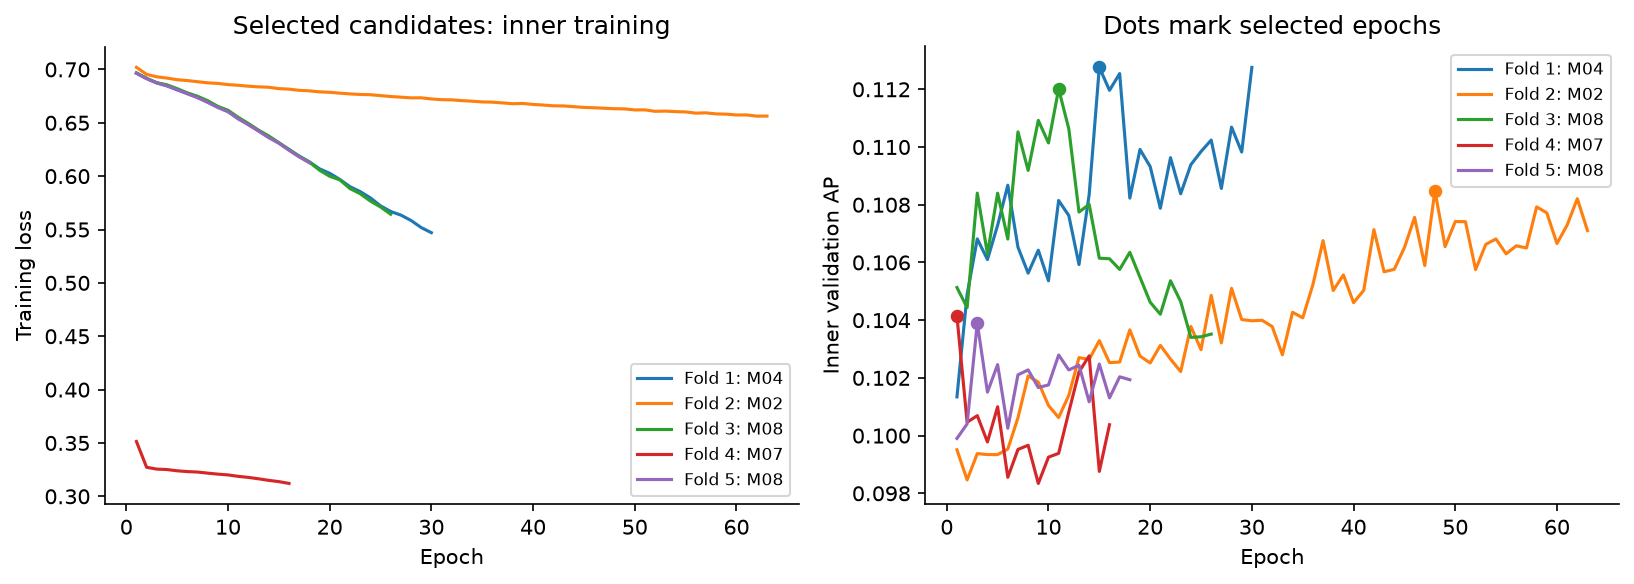

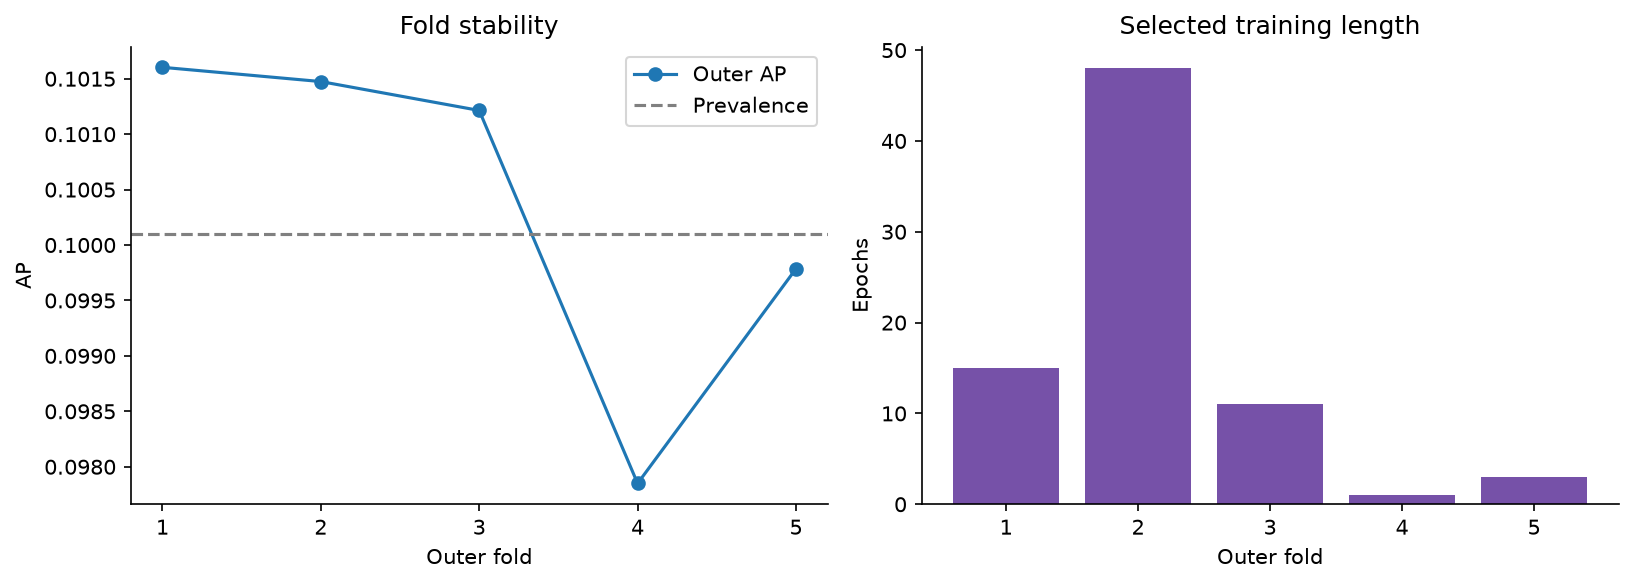

In [6]:
display(Image(filename=str(out / "learning_curves.png")))
display(Image(filename=str(out / "fold_results.png")))

The learning curves show the selected candidates during inner training. Dots mark the chosen epochs. They are measured curves, not reconstructed curves. The winner refits have separate loss histories and no validation stopping.

## 6. Final MLP results
Pooled AP evaluates all OOF scores together. Mean fold AP averages the five round scores. Higher AP and ROC-AUC are better; lower Brier is better. Precision, recall and F1 below use the fixed threshold of 0.50.

,Metric,Value
0,Pooled AP,0.100422
1,Mean fold AP,0.100385
2,Fold AP standard deviation,0.001593
3,ROC-AUC,0.499555
4,Brier score,0.204095
5,Precision at 0.50,0.098572
6,Recall at 0.50,0.283591
7,F1 at 0.50,0.146294
8,Accuracy at 0.50,0.668687


Reference: AP = 0.1001; ROC-AUC = 0.5; Brier = 0.09007999.


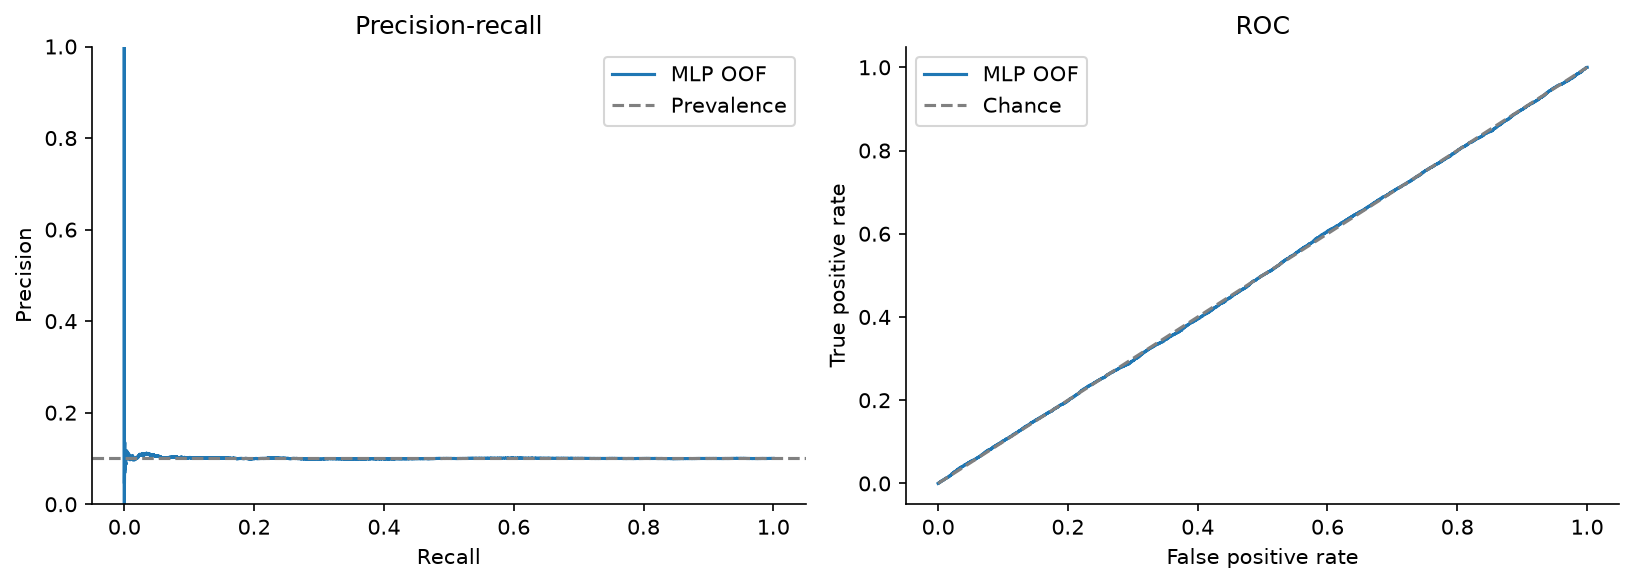

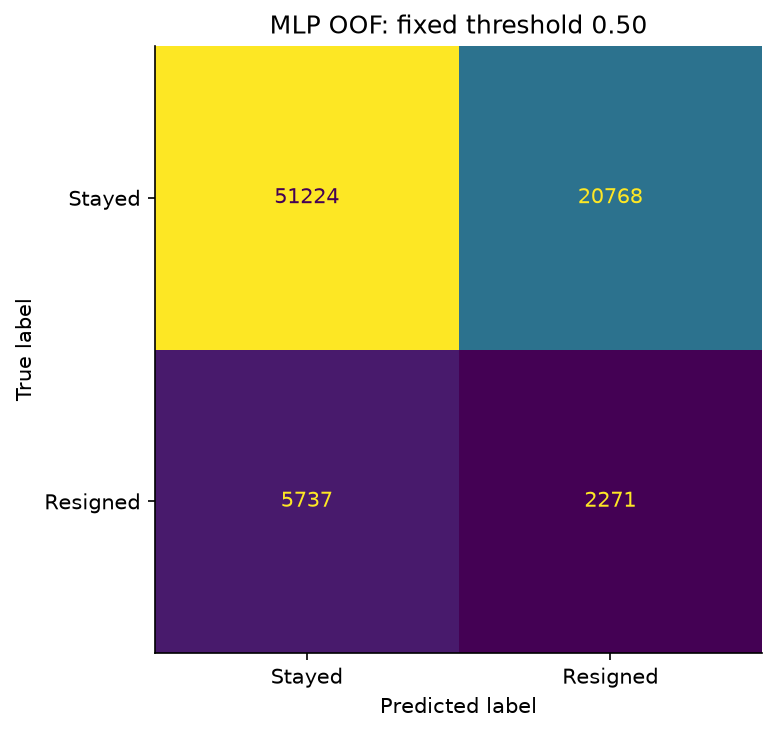

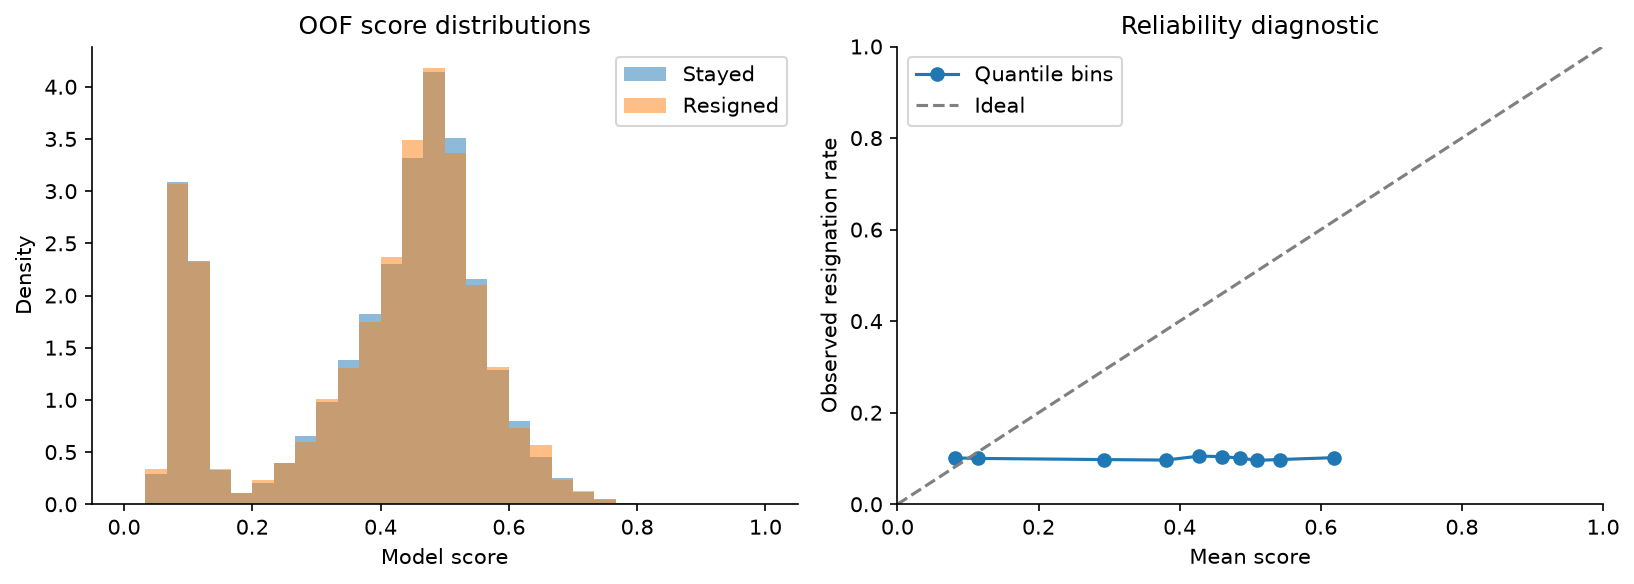

In [7]:
metric_names = {"average_precision": "Pooled AP", "mean_fold_ap": "Mean fold AP",
    "sd_fold_ap": "Fold AP standard deviation", "roc_auc": "ROC-AUC", "brier_score": "Brier score",
    "precision": "Precision at 0.50", "recall": "Recall at 0.50", "f1": "F1 at 0.50", "accuracy": "Accuracy at 0.50"}
display(pd.DataFrame([{"Metric": label, "Value": summary[key]} for key, label in metric_names.items()]))
print("Reference: AP = 0.1001; ROC-AUC = 0.5; Brier = 0.09007999.")
display(Image(filename=str(out / "ranking_curves.png")))
display(Image(filename=str(out / "confusion_matrix.png")))
display(Image(filename=str(out / "probability_diagnostics.png")))

The dashed PR line is the resignation rate; the dashed ROC line is chance ranking. The confusion matrix counts correct and incorrect decisions at 0.50. The score distributions and reliability plot help assess probability error. Weighting may change calibration, so sigmoid scores are not automatically trustworthy probabilities.

## 7. Comparison with the existing models
This table uses current registered OOF evidence on the same development employees, including the updated CatBoost results. Tuning methods differ, so these numbers compare measured procedures rather than isolating the effect of architecture. Small numerical differences do not establish practical superiority.

In [8]:
comparison = pd.read_csv(out / "model_comparison.csv")
display(comparison.rename(columns={"average_precision": "Pooled AP", "roc_auc": "ROC-AUC", "brier_score": "Brier"}))

,Model,Pooled AP,ROC-AUC,Brier
0,CatBoost,0.102248,0.504103,0.090077
1,XGBoost,0.101181,0.502471,0.175329
2,MLP (supplementary),0.100422,0.499555,0.204095
3,LightGBM,0.100153,0.498740,0.180215
4,Constant prevalence reference,0.100100,0.500000,0.090080
5,TabNet,0.099965,0.499317,0.186177
6,EBM,0.099000,0.495976,0.090109
7,FT-Transformer,0.098648,0.497980,0.153086


## 8. Conclusion and limitations
In this recorded run, MLP ranking was close to chance and probability error was worse than the constant-prevalence reference. It did not show useful ranking performance on these inputs. Interpret the measured results above against AP 0.1001, ROC-AUC 0.5 and Brier 0.09007999. Fold winners can differ in weighting and score scale, so pooled AP can differ from mean fold AP.

This is one seed and eight settings. Dataset provenance and prediction horizon are unverified. Salary redundancy and sensitive attributes need further investigation. No MLP significance test, fairness assessment, calibration fitting or holdout evaluation was performed.

Possible next steps are better verified predictors, repeated inner splits and training-only calibration. The existing holdout must stay out of those choices.

**Viva explanation:** “I tested eight MLP settings in each of five rounds. Inner validation chose the setting and epoch count. A fresh winner then trained on the full training portion and predicted the reserved fold. We used training-only scaling and one-hot encoding, and compared weighted and unweighted loss.”

Implementation and dependencies: Python, NumPy, pandas, scikit-learn >=1.7, matplotlib, PyYAML and threadpoolctl; Jupyter/IPython for review. No new heavy dependencies were installed. See reports/IT25100142_MLP_Experiment.md for the full report and evidence paths. Source: [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).

In [9]:
assert len(selection) == 40
assert len(fold_metrics) == 5
assert selection.groupby("outer_fold").size().eq(8).all()
assert summary["total_fits"] == 45 and summary["development_rows"] == 80000
assert not summary["formal_holdout_evaluated"]
print("Saved aggregate checks passed: 40 candidate records, 5 winners, 45 fits, 80,000 OOF records.")
print("Exact OOF metrics were recomputed during validation; this review cell checks saved aggregates.")

Saved aggregate checks passed: 40 candidate records, 5 winners, 45 fits, 80,000 OOF records.
Exact OOF metrics were recomputed during validation; this review cell checks saved aggregates.
